**Important: read the following before you hit "Run all"**

Model checkpoints will be saved and loaded locally.

This notebook uses Google Colab. So, `local` means local disk used in the current Google Colab session.

To persist model checkpoints across sessions, this notebook saves the local copy to Google Drive after training.

To load a model back, this notebook copies model checkpoints from Google Drive back to Google Colab.

To transfer data between Google Colab and Google Drive, Google Drive is mounted under "/content/drive" and our data can be accessed via "/content/drive/MyDrive" in Google Colab.

**Checkpoints needed for training:**

R1 checkpoints on Google Drive: /checkpoints/r1_checkpoints

E1 checkpoints on Google Drive: /checkpoints/sft_sst2_gpt2_E1-1_2logits

**Final model saved after training:**

R3 on Google Drive: /checkpoints/r3_checkpoints/r3-grpo-final

**Note**:

1) Change these locations and files operations to match your environments as necessary. For example, you may mount your Google Drive, then load and save checkpoints directly from Google Drive. Though, load & save on local + copy before load & save after training between Google Colab and Google Drive as described above is preferred.

2) Multiple checkpoints will be saved during training, which will consume a lot of disk space. Therefore, unless we want these checkpoints for resumption or continuous training across Google Colab sessions, we should only copy the final model from Google Colab to Google Drive. Otherwise, you may find out it would eat up your Google Drive space pretty fast.

In [ ]:
# First, mount Drive (run in a cell)
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Copy R1 & E1 from Google Drive to local

!cp -r drive/MyDrive/checkpoints/r1_checkpoints/ .

!cp -r drive/MyDrive/checkpoints/sft_sst2_gpt2_E1-1_2logits .


In [ ]:
!pip install trl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 996.6/996.6 kB 36.9 MB/s  0:00:00


In [ ]:
# Prepare the R3 prompt dataset
import math
import random
import torch

from datasets import load_dataset, Dataset

from transformers import (
    AutoTokenizer,
    GPT2LMHeadModel,
    GPT2Model,
    set_seed,
)

# --------------------------------------------------
# Configuration
# --------------------------------------------------

R3_TRAIN_PROMPTS = 1000
R3_VALIDATION_PROMPTS = 100

SEED = 42

SENTIMENT_NAMES = {
    0: "negative",
    1: "positive"
}

set_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print(f"Device: {DEVICE}")

# --------------------------------------------------
# Create sentiment-conditioned prompts
# --------------------------------------------------

def create_grpo_prompts(split, num_examples, seed):

    source_dataset = load_dataset(
        "stanfordnlp/sst2",
        split=split
    )

    rng = random.Random(seed)

    prompt_records = []

    for example in source_dataset:

        words = example["sentence"].split()

        if len(words) < 8:
            continue

        # Randomly retain 50%-70% as the prefix.
        min_split = max(4, math.ceil(len(words) * 0.50))
        max_split = min(
            len(words) - 3,
            math.floor(len(words) * 0.70)
        )

        if min_split > max_split:
            continue

        split_index = rng.randint(min_split, max_split)

        prefix = " ".join(words[:split_index])

        sentiment = SENTIMENT_NAMES[example["label"]]

        prompt = (
            f"Sentiment: {sentiment}\n"
            f"Continue the following review:\n"
            f"{prefix}"
        )

        prompt_records.append({
            "prompt": prompt
        })

        if len(prompt_records) >= num_examples:
            break

    return Dataset.from_list(prompt_records)


train_dataset = create_grpo_prompts(
    split="train",
    num_examples=R3_TRAIN_PROMPTS,
    seed=SEED
)

validation_dataset = create_grpo_prompts(
    split="validation",
    num_examples=R3_VALIDATION_PROMPTS,
    seed=SEED + 1
)

print("Training prompts:", len(train_dataset))
print("Validation prompts:", len(validation_dataset))

print("\nExample prompt:")
print(train_dataset[0]["prompt"])

Device: cuda


README.md:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

Training prompts: 1000
Validation prompts: 100

Example prompt:
Sentiment: positive
Continue the following review:
that loves its characters and communicates something rather


In [ ]:
# Load the E1 reward model
import os
from torch import nn

MODEL_NAME = "openai-community/gpt2"

E1_CHECKPOINT = "./sft_sst2_gpt2_E1-1_2logits"
E1_CHECKPOINT_WEIGHTS_FILE = "final_model_weights.pth"

# Load E1 - the sentiment classifier, used to classify sentiment of texts to determine "chosen" and "rejected"
# can be thinked of as a reward model


# Load the tokenizer (it knows how to reconstruct itself from the folder)
reward_tokenizer = AutoTokenizer.from_pretrained(E1_CHECKPOINT)


# ============================================================
# Model
# ============================================================

class GPT2SentimentClassifier(nn.Module):

    def __init__(self, model_name, num_labels=2):
        super().__init__()

        # GPT-2 WITHOUT the language-model head.
        self.gpt2 = GPT2Model.from_pretrained(model_name)

        hidden_size = self.gpt2.config.hidden_size

        # Binary classification head:
        #
        # [B, 768] -> [B, 2]
        self.classifier = nn.Linear(
            hidden_size,
            num_labels,
        )


    def forward(self, input_ids, attention_mask, labels=None):

        # ----------------------------------------------------
        # GPT-2
        #
        # last_hidden_state:
        # [B, T, 768]
        # ----------------------------------------------------

        outputs = self.gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )

        hidden_states = outputs.last_hidden_state

        # ----------------------------------------------------
        # Find the position of the last real token
        #
        # attention_mask:
        #
        #   1 1 1 1 1 0 0
        #
        # last real token = position 4
        # ----------------------------------------------------

        sequence_lengths = attention_mask.sum(dim=1) - 1

        batch_indices = torch.arange(
            hidden_states.size(0),
            device=hidden_states.device,
        )

        # [B, 768]
        pooled_hidden_states = hidden_states[
            batch_indices,
            sequence_lengths,
        ]

        # ----------------------------------------------------
        # Classification head
        #
        # [B, 768] -> [B, 2]
        # ----------------------------------------------------

        logits = self.classifier(
            pooled_hidden_states
        )


        # ----------------------------------------------------
        # Classification loss
        # ----------------------------------------------------

        loss = None

        if labels is not None:
            loss_fn = nn.CrossEntropyLoss()
            loss = loss_fn(logits, labels)

        return {
            "loss": loss,
            "logits": logits,
        }

# 2. Initialize our model class (we know the architecture)
reward_model = GPT2SentimentClassifier(
    MODEL_NAME,
    num_labels=2,
)

# 3. Load the saved weights and freeze
reward_checkpoint = torch.load(os.path.join(E1_CHECKPOINT, E1_CHECKPOINT_WEIGHTS_FILE), weights_only=True)
reward_model.load_state_dict(reward_checkpoint['model_state_dict'])
reward_model.to(DEVICE)
reward_model.eval()

for parameter in reward_model.parameters():
    parameter.requires_grad = False

print("E1 reward model loaded.")
print("Device:", DEVICE)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

E1 reward model loaded.
Device: cuda


In [ ]:
# Reward function

import re
import torch.nn.functional as F


MAX_E1_LENGTH = 128
E1_BATCH_SIZE = 32


def sentiment_reward_func(prompts, completions, **kwargs):

    review_texts = []
    target_labels = []

    for prompt, completion in zip(prompts, completions):

        # Extract requested sentiment.
        match = re.search(
            r"Sentiment:\s*(positive|negative)",
            prompt,
            re.IGNORECASE
        )

        if match is None:
            raise ValueError(
                f"Could not extract sentiment from prompt: {prompt}"
            )

        sentiment = match.group(1).lower()

        target_label = {
            "negative": 0,
            "positive": 1
        }[sentiment]

        target_labels.append(target_label)

        # Extract original review prefix.
        marker = "Continue the following review:\n"

        if marker not in prompt:
            raise ValueError(
                f"Could not extract review prefix: {prompt}"
            )

        prefix = prompt.split(marker, 1)[1]

        # Score the complete review.
        review = prefix + completion

        review_texts.append(review)

    all_rewards = []

    # Batch E1 inference to avoid excessive GPU memory usage.
    for start in range(0, len(review_texts), E1_BATCH_SIZE):

        end = start + E1_BATCH_SIZE

        batch_texts = review_texts[start:end]
        batch_targets = target_labels[start:end]

        inputs = reward_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=MAX_E1_LENGTH,
            return_tensors="pt"
        ).to(DEVICE)

        with torch.no_grad():

            outputs = reward_model(
                input_ids=inputs["input_ids"],
                attention_mask=inputs["attention_mask"]
            )

            logits = outputs["logits"]

            probabilities = F.softmax(
                logits,
                dim=-1
            )

            target_indices = torch.tensor(
                batch_targets,
                dtype=torch.long,
                device=DEVICE
            )

            rewards = probabilities.gather(
                dim=1,
                index=target_indices.unsqueeze(1)
            ).squeeze(1)

        all_rewards.extend(
            rewards.cpu().tolist()
        )

    return all_rewards

In [ ]:
# Test the reward function before training
# I strongly recommend testing it independently.

test_prompts = [
    (
        "Sentiment: positive\n"
        "Continue the following review:\n"
        "that loves its characters and communicates something"
    ),
    (
        "Sentiment: negative\n"
        "Continue the following review:\n"
        "that loves its characters and communicates something"
    )
]

test_completions = [
    " very special about humankind",
    " that is really, truly unpleasant"
]

test_rewards = sentiment_reward_func(
    prompts=test_prompts,
    completions=test_completions
)

for prompt, completion, reward in zip(
    test_prompts,
    test_completions,
    test_rewards
):

    print("\nPrompt:", prompt)
    print("Completion:", completion)
    print("Reward:", round(reward, 4))


Prompt: Sentiment: positive
Continue the following review:
that loves its characters and communicates something
Completion:  very special about humankind
Reward: 0.6166

Prompt: Sentiment: negative
Continue the following review:
that loves its characters and communicates something
Completion:  that is really, truly unpleasant
Reward: 0.5819


In [ ]:
# Configure and run GRPOTrainer

from pathlib import Path
from transformers import (
    AutoTokenizer,
    GPT2LMHeadModel,
    set_seed
)

from trl import GRPOConfig, GRPOTrainer
from transformers.trainer_utils import get_last_checkpoint


# --------------------------------------------------
# Configuration
# --------------------------------------------------

R1_CHECKPOINT = "./r1_checkpoints/r1-sft-best"

CHECKPOINT_ROOT = Path("./r3_checkpoints")

RUN_NAME = "run_01"

OUTPUT_DIR = CHECKPOINT_ROOT / "runs" / RUN_NAME

FINAL_MODEL_DIR = CHECKPOINT_ROOT / "r3-grpo-final"


# --------------------------------------------------
# Hyperparameters
# --------------------------------------------------

NUM_TRAIN_EPOCHS = 1

PER_DEVICE_TRAIN_BATCH_SIZE = 4
PER_DEVICE_EVAL_BATCH_SIZE = 4

GRADIENT_ACCUMULATION_STEPS = 1

NUM_GENERATIONS = 4

LEARNING_RATE = 1e-6

BETA = 0.04

MAX_PROMPT_LENGTH = 120
MAX_COMPLETION_LENGTH = 40

WARMUP_STEPS = 10

LOGGING_STEPS = 5
SAVE_EVAL_STEPS = 50

SEED = 42


# --------------------------------------------------
# Reproducibility
# --------------------------------------------------

set_seed(SEED)


# --------------------------------------------------
# Load tokenizer
# --------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(
    R1_CHECKPOINT
)

tokenizer.pad_token = tokenizer.eos_token

# GRPOTrainer requires left padding.
tokenizer.padding_side = "left"


# --------------------------------------------------
# Load initial policy: R1
# --------------------------------------------------

policy_model = GPT2LMHeadModel.from_pretrained(
    R1_CHECKPOINT
)

policy_model.config.pad_token_id = tokenizer.pad_token_id

policy_model.config.use_cache = False


# --------------------------------------------------
# GRPO configuration
# --------------------------------------------------

training_args = GRPOConfig(

    output_dir=str(OUTPUT_DIR),

    run_name=RUN_NAME,

    # Training duration.
    num_train_epochs=NUM_TRAIN_EPOCHS,

    # Batch settings.
    per_device_train_batch_size=PER_DEVICE_TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=PER_DEVICE_EVAL_BATCH_SIZE,

    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,

    # Online generation.
    num_generations=NUM_GENERATIONS,
    num_generations_eval=NUM_GENERATIONS,

    #max_prompt_length=MAX_PROMPT_LENGTH,
    max_completion_length=MAX_COMPLETION_LENGTH,

    temperature=0.9,
    top_p=0.95,
    repetition_penalty=1.0,

    # GRPO objective.
    beta=BETA,
    loss_type="grpo",
    scale_rewards="group",

    # Optimizer.
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    optim="adamw_torch",

    lr_scheduler_type="cosine",
    warmup_steps=WARMUP_STEPS,

    max_grad_norm=1.0,

    # Evaluation.
    eval_strategy="steps",
    eval_steps=SAVE_EVAL_STEPS,

    # Checkpointing.
    save_strategy="steps",
    save_steps=SAVE_EVAL_STEPS,
    save_total_limit=2,

    # Logging.
    logging_strategy="steps",
    logging_steps=LOGGING_STEPS,
    logging_first_step=True,

    disable_tqdm=False,
    report_to="none",

    # Hardware.
    fp16=torch.cuda.is_available(),
    bf16=False,

    gradient_checkpointing=False,

    dataloader_num_workers=0,

    # Dataset.
    remove_unused_columns=False,

    # Reproducibility.
    seed=SEED,
    data_seed=SEED,

)


# --------------------------------------------------
# Create GRPO trainer
# --------------------------------------------------

trainer = GRPOTrainer(

    model=policy_model,

    reward_funcs=sentiment_reward_func,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=validation_dataset,

    processing_class=tokenizer
)


# --------------------------------------------------
# Train
# --------------------------------------------------

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

last_checkpoint = get_last_checkpoint(
    str(OUTPUT_DIR)
)

if last_checkpoint:

    print("Resuming from:", last_checkpoint)

    train_result = trainer.train(
        resume_from_checkpoint=last_checkpoint
    )

else:

    print("Starting new R3 GRPO training run.")

    train_result = trainer.train()


# --------------------------------------------------
# Save final model
# --------------------------------------------------

trainer.save_model(
    str(FINAL_MODEL_DIR)
)

tokenizer.save_pretrained(
    str(FINAL_MODEL_DIR)
)


# --------------------------------------------------
# Evaluate
# --------------------------------------------------

eval_metrics = trainer.evaluate()

print("\n========== R3 GRPO Evaluation ==========")

for key, value in eval_metrics.items():

    if isinstance(value, (int, float)):
        print(f"{key}: {value:.6f}")

print("========================================")

print("\nR3 final model saved to:", FINAL_MODEL_DIR)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Starting new R3 GRPO training run.


Step,Training Loss,Validation Loss,Num Tokens,Completions/mean Length,Completions/min Length,Completions/max Length,Completions/clipped Ratio,Completions/mean Terminated Length,Completions/min Terminated Length,Completions/max Terminated Length,Rewards/sentiment Reward Func/mean,Rewards/sentiment Reward Func/std,Reward,Reward Std,Frac Reward Zero Std,Kl,Entropy,Clip Ratio/low Mean,Clip Ratio/high Mean,Clip Ratio/region Mean,Clip Ratio/low Min,Clip Ratio/high Max
50,0.275185,0.000020,5934.000000,7.222500,3.350000,13.100000,0.000000,7.222500,3.350000,13.100000,0.624689,0.101980,0.624689,0.101980,0.030000,0.000393,2.844358,0.000000,0.000000,0.000000,0.000000,0.000000
100,0.006844,0.000048,11672.000000,7.262500,3.490000,12.650000,0.002500,7.193333,3.490000,12.410000,0.620207,0.095608,0.620207,0.095608,0.040000,0.000897,2.795821,0.000000,0.000000,0.000000,0.000000,0.000000
150,0.036072,0.000091,17507.000000,7.657500,3.690000,13.280000,0.002500,7.572500,3.690000,12.980000,0.613997,0.110621,0.613997,0.110621,0.040000,0.001715,2.841632,0.000000,0.000000,0.000000,0.000000,0.000000
200,0.013687,0.000105,23663.000000,7.635000,3.610000,13.020000,0.000000,7.635000,3.610000,13.020000,0.618364,0.106109,0.618364,0.106109,0.040000,0.002077,2.767062,0.000000,0.000000,0.000000,0.000000,0.000000
250,0.027975,0.000085,29639.000000,7.265000,3.590000,12.540000,0.000000,7.265000,3.590000,12.540000,0.615616,0.099854,0.615616,0.099854,0.030000,0.001737,2.851107,0.000000,0.000000,0.000000,0.000000,0.000000
300,0.010647,0.000074,36034.000000,7.665000,3.400000,13.770000,0.002500,7.596667,3.400000,13.550000,0.606576,0.107646,0.606576,0.107646,0.040000,0.001567,2.814010,0.000000,0.000000,0.000000,0.000000,0.000000
350,0.043277,0.000089,41784.000000,7.222500,3.680000,12.630000,0.002500,7.159167,3.680000,12.470000,0.609577,0.104096,0.609577,0.104096,0.050000,0.002015,2.826514,0.000000,0.000000,0.000000,0.000000,0.000000
400,0.008783,0.000096,47644.000000,7.642500,3.950000,12.900000,0.002500,7.570000,3.950000,12.660000,0.621248,0.111946,0.621248,0.111946,0.010000,0.002142,2.860372,0.000000,0.000000,0.000000,0.000000,0.000000
450,0.011616,0.000117,53878.000000,7.385000,3.460000,13.010000,0.000000,7.385000,3.460000,13.010000,0.625946,0.106296,0.625946,0.106296,0.010000,0.002553,2.850708,0.000000,0.000000,0.000000,0.000000,0.000000
500,0.007829,0.000133,59707.000000,7.332500,3.590000,12.690000,0.002500,7.242500,3.590000,12.330000,0.613157,0.105696,0.613157,0.105696,0.030000,0.002957,2.767116,0.000000,0.000000,0.000000,0.000000,0.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (17 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Step,Num Tokens,Completions/mean Length,Completions/min Length,Completions/max Length,Completions/clipped Ratio,Completions/mean Terminated Length,Completions/min Terminated Length,Completions/max Terminated Length,Rewards/sentiment Reward Func/mean,Rewards/sentiment Reward Func/std,Reward,Reward Std,Frac Reward Zero Std,Kl,Entropy,Clip Ratio/low Mean,Clip Ratio/high Mean,Clip Ratio/region Mean,Clip Ratio/low Min,Clip Ratio/high Max
0.014628,0.000255,1000,120060.000000,7.952500,3.920000,13.910000,0.000000,7.952500,3.920000,13.910000,0.630393,0.091017,0.630393,0.091017,0.010000,0.005166,2.838293,0.000000,0.000000,0.000000,0.000000,0.000000



========== R3 GRPO Evaluation ==========
eval_loss: 0.000255
eval_num_tokens: 120060.000000
eval_completions/mean_length: 7.952500
eval_completions/min_length: 3.920000
eval_completions/max_length: 13.910000
eval_completions/clipped_ratio: 0.000000
eval_completions/mean_terminated_length: 7.952500
eval_completions/min_terminated_length: 3.920000
eval_completions/max_terminated_length: 13.910000
eval_rewards/sentiment_reward_func/mean: 0.630393
eval_rewards/sentiment_reward_func/std: 0.091017
eval_reward: 0.630393
eval_reward_std: 0.091017
eval_frac_reward_zero_std: 0.010000
eval_kl: 0.005166
eval_entropy: 2.838293
eval_clip_ratio/low_mean: 0.000000
eval_clip_ratio/high_mean: 0.000000
eval_clip_ratio/region_mean: 0.000000
eval_clip_ratio/low_min: 0.000000
eval_clip_ratio/high_max: 0.000000

R3 final model saved to: r3_checkpoints/r3-grpo-final


In [ ]:
# save r3 to Google Drive

# If we have enough storage to use on our Google Drive, save checkpoints and final model
!cp -r ./r3_checkpoints drive/MyDrive/checkpoints

# Otherwise, save final model
!cp -r ./r3_checkpoints/r3-grpo-final drive/MyDrive/checkpoints/r3_checkpoints/

In [ ]:
# Load R3 for generation

from transformers import AutoTokenizer, GPT2LMHeadModel

R3_MODEL_PATH = "./r3_checkpoints/r3-grpo-final"

r3_tokenizer = AutoTokenizer.from_pretrained(
    R3_MODEL_PATH
)

r3_model = GPT2LMHeadModel.from_pretrained(
    R3_MODEL_PATH
).to(DEVICE)

r3_model.eval()

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [ ]:
# A common continuation generation function to be used for all experiments (models), making a comparison across them fairer

def generate_continuation(
    model,
    tokenizer,
    sentiment,
    prefix,
    max_new_tokens=40
):
    """
    Generate a sentiment-conditioned continuation.

    Args:
        model: Hugging Face causal language model.
        tokenizer: Corresponding tokenizer.
        sentiment: "positive" or "negative".
        prefix: Review prefix to continue.
        max_new_tokens: Maximum number of new tokens.

    Returns:
        Generated continuation (without the original prompt).
    """

    # Construct prompt exactly as in R1 and R2.
    prompt = (
        f"Sentiment: {sentiment}\n"
        f"Continue the following review:\n"
        f"{prefix}"
    )

    # Determine model device.
    device = next(model.parameters()).device

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(device)

    model.eval()

    with torch.no_grad():

        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            temperature=0.8,
            top_p=0.9,
            repetition_penalty=1.1,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    # Remove prompt tokens to obtain continuation only.
    prompt_length = inputs["input_ids"].shape[1]

    continuation_ids = output_ids[0, prompt_length:]

    continuation = tokenizer.decode(
        continuation_ids,
        skip_special_tokens=True
    )

    return continuation

In [ ]:
# Test

prefix = "that loves its characters and communicates something"

for sentiment in ["positive", "negative"]:

    continuation = generate_continuation(
        model=r3_model,
        tokenizer=r3_tokenizer,
        sentiment=sentiment,
        prefix=prefix,
        max_new_tokens=40
    )

    print(f"\nR3 - {sentiment.capitalize()}:")
    print(continuation)


R3 - Positive:
 very human about them

R3 - Negative:
 that feels less like a movie


**Metrics interpretation and model behavior assessment**

R3 is a successful GRPO implementation experiment, and the training appears stable, but the results do not yet demonstrate that GRPO improved R1. I would call this a useful first GRPO run, with some encouraging signals, rather than a demonstrated post-training improvement.

There are several things worth examining.

**1. Reward behavior: stable, but not improving**

Our training reward starts at approximately 0.625 and fluctuates around 0.61–0.63 throughout the 1,000 steps.

**R3 training reward**\
Mean sentiment reward at each logged training step.

[50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 600, 650, 700, 750, 800, 850, 900, 950, 1000]


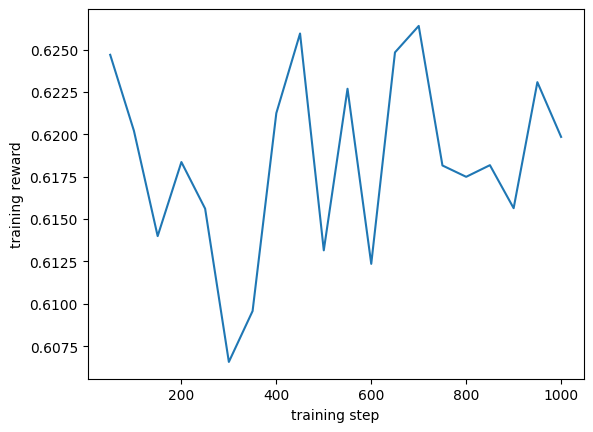

In [ ]:
steps = list(range(50, 1050, 50))
training_reward = [0.624689, 0.620207, 0.613997, 0.618364,0.615616,0.606576,0.609577,0.621248,0.625946,0.613157,0.622687,0.61236,0.624832,0.626393,0.618162,0.617493,0.61818,0.615643,0.623076,0.619847]
print(steps)

import matplotlib.pyplot as plt

plt.plot(steps, training_reward)
plt.xlabel("training step")
plt.ylabel("training reward")
plt.show()

The key observation is that there is **no convincing upward trend**.

The final evaluation reward is `0.630393`, which is reasonably close to the training reward. That is encouraging in terms of consistency, but we don't have an initial R1 evaluation reward measured on the same validation prompts. Consequently, we cannot tell whether GRPO improved the policy's sentiment performance.

The reward standard deviation is around `0.09`, so there is still meaningful variation in reward across generated completions. That gives GRPO something to optimize.

The `eval_frac_reward_zero_std` of `0.01` is also encouraging: only `1%` of the evaluation groups had zero reward standard deviation. In other words, most groups had some reward variation among their generated completions.

**Interpretation**: the reward signal is usable, but the logs do not show that the policy learned to exploit it more effectively.

**2. KL and entropy: the policy remained relatively stable**

Two metrics are particularly interesting:
```
Metric	Step 50   Step 1,000
KL      0.000393  0.004727
Entropy 2.844     2.843
```
KL increased slightly, but remained small. This suggests that the trained policy did not move very far from its reference policy.

Entropy also remained remarkably stable. There is no obvious sign of the policy collapsing into a narrow set of completions.

These are generally desirable properties for a first GRPO experiment. However, they also suggest that the policy update was relatively conservative.

One other observation: all the reported clipping-ratio metrics are zero. This means the logged clipping statistics did not register any clipped updates. That is worth investigating, although it is not sufficient by itself to conclude that GRPO was malfunctioning. It may simply reflect small policy updates.

**3. Don't interpret the tiny training and evaluation losses as success**

Our final evaluation loss is:
```
eval_loss: 0.000255
```

And the training loss fluctuates between approximately `0.007` and `0.04` for most of the run, with occasional larger values.

We would not use these numbers to judge whether GRPO succeeded.

This is an important distinction between our `R2` DPO and `R3` GRPO experiments.

- In R2, DPO loss is directly associated with the chosen/rejected preference objective. Its downward trend, combined with improving preference accuracy and reward margin, provided useful evidence of learning.
- In R3, the GRPO loss is associated with a policy optimization objective involving group-relative advantages. Its magnitude is not directly comparable to supervised cross-entropy or DPO loss.

A tiny GRPO loss does not mean the generated continuations are excellent, nor does it mean the policy has learned the requested sentiment.

**4. The generated continuations: some encouraging behavior, but inconclusive**

Our R3 outputs:
```
Requested sentiment   R3 continuation
-------------------   ---------------
Positive              very human about them
Negative              that feels less like a movie
```

Qualitative assessment:

**Positive**: "very human about them" is mildly positive in tone, but it is not particularly strong or explicit. It could also be neutral depending on context.

**Negative**: "that feels less like a movie" is not necessarily negative. It could be a criticism, but it could also be a positive observation about a movie that feels realistic.

So, neither output provides convincing evidence of sentiment control.

There is another interesting comparison with our earlier R1 and R2 examples for this same prefix:

```
Model    Positive                 Negative
-----    --------                 --------         
R1       about humanity           that is utterly insufferable
R2       fresh, engaging          utterly bad
R3       very human about them    that feels less like a movie
```

R1 and R2 produced more recognizable sentiment differences in these examples. R3 has not demonstrated an improvement over either.

Of course, these are individual stochastic samples, not a statistically meaningful comparison. We would not conclude that R3 is worse based on them.

**5. What do the reward-function tests tell us?**
```
Requested sentiment Completion                          Reward
------------------- ----------                          ------
Positive            very special about humankind        0.6166
Negative            that is really, truly unpleasant    0.5819
```

These are useful sanity checks: the reward function produces different scores for different requested sentiments and completions.

But we would like to highlight something important.

The reward is the E1 classifier's probability of the requested sentiment. It is not a direct measure of how good a continuation is.

For example, the positive completion scores 0.6166 and the negative completion scores 0.5819. These scores are not directly comparable as measures of positive versus negative sentiment, because each score refers to a different requested class.

More importantly, these two tests do not establish that R3's own generated completions receive better rewards than R1's completions.

We should evaluate that explicitly.

**6. Overall verdict**

- Implementation milestone achieved
- Performance improvement unproven


We would assess the experiment as follows:
```
Aspect	                                        Assessment
-----------------------                         ----------
GRPO training completed                         Success
Training stability                              Encouraging
Reward signal variation                         Encouraging
Policy remained close to reference              Yes
Evidence of reward improvement during training  Weak
Evidence of improved sentiment adherence        Not established
Evidence of improved generation quality         Not established
```
There is an important educational achievement here: we have now implemented three different post-training approaches around the same GPT-2 conditional continuation task.

- R1: supervised fine-tuning.
- R2: offline preference optimization with DPO.
- R3: online group-relative policy optimization with GRPO.

That is already a valuable progression for understanding how different post-training methods work.